# VN Traffic AI — Notebook end-to-end (1 vòng fine-tune)

**Chủ đề 10**: Phát hiện, theo vết và đếm phương tiện giao thông Việt Nam từ video.

Notebook này thay thế cho các file `MASTER_full_project.ipynb`, `demo_full_pipeline.ipynb`, `learn_pipeline_from_scratch.ipynb`, `report_baseline_vs_improved.ipynb` — gom tất cả vào **1 file duy nhất**, chạy được end-to-end.

## Chiến lược khác so với phiên bản trước

Trước đây train **2 vòng**:
1. `train_v8s_4cls`: yolov8s.pt → merged (UA-DETRAC + CanTho), lr 0.01, 50 epochs
2. `train_v8s_ft_vnv3`: continual từ best.pt vòng 1 + thêm vnv3, lr 0.001, 25 epochs

Bây giờ train **1 vòng gộp** trên toàn bộ merged (UA-DETRAC + CanTho + vnv3):
- Đỡ nguy cơ *catastrophic forgetting* giữa 2 vòng.
- Ít siêu tham số phải tune, dễ reproduce.
- Đánh đổi: mất "câu chuyện" boost xe máy từ vnv3 (nếu cần narrative đó thì giữ 2 vòng).

## Mục lục
1. Setup môi trường + GPU check
2. Data prep (đảm bảo merged sẵn sàng)
3. EDA nhanh — phân bố class
4. Training (1 vòng, gọi Ultralytics API trực tiếp)
5. Evaluation mAP trên val set
6. Inference + tracking + counting trên video demo
7. So sánh baseline (COCO) vs improved (fine-tune)
8. Tổng kết + hạn chế + hướng phát triển

> ⚠️ **Lưu ý về training**: cell train ~3-5h trên RTX 3500 Ada 12GB. Nếu chỉ muốn xem kết quả, **skip cell train và dùng weights có sẵn** ở `runs/detect/runs/detect/train_v8s_ft_vnv3/weights/best.pt` (đã có sẵn từ lần train trước).

---
## Phần 1 — Setup môi trường

In [1]:
# Import + check GPU
import os, sys, json, subprocess
from pathlib import Path

import torch
import ultralytics
from ultralytics import YOLO

print(f"Python  : {sys.version.split()[0]}")
print(f"Torch   : {torch.__version__}")
print(f"CUDA    : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU     : {torch.cuda.get_device_name(0)}")
    print(f"VRAM    : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"Ultralytics: {ultralytics.__version__}")

Python  : 3.10.20
Torch   : 2.5.1+cu124
CUDA    : True
GPU     : NVIDIA RTX 3500 Ada Generation Laptop GPU
VRAM    : 12.9 GB
Ultralytics: 8.4.142


In [2]:
# Chuẩn hoá cwd = project root (notebook nằm ở notebooks/)
PROJECT_ROOT = Path("/home/xuand/vn_traffic_ai").resolve()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

DATA_YAML   = PROJECT_ROOT / "data" / "data.yaml"
MERGED_DIR  = PROJECT_ROOT / "data" / "merged"
WEIGHTS_DIR = PROJECT_ROOT / "weights"
RUNS_DIR    = PROJECT_ROOT / "runs" / "detect"
DEMO_VIDEO  = PROJECT_ROOT / "data" / "test_videos" / "raw" / "demo_traffic.mp4"
DEMO_GT     = PROJECT_ROOT / "data" / "test_videos" / "ground_truth" / "demo_traffic.json"

assert DATA_YAML.exists(), f"Thiếu {DATA_YAML} — chạy scripts/data_prep/setup_datasets.sh trước"
assert DEMO_VIDEO.exists(), f"Thiếu video test {DEMO_VIDEO}"
print(f"[OK] PROJECT_ROOT = {PROJECT_ROOT}")
print(f"[OK] data.yaml    = {DATA_YAML}")

[OK] PROJECT_ROOT = /home/xuand/vn_traffic_ai
[OK] data.yaml    = /home/xuand/vn_traffic_ai/data/data.yaml


---
## Phần 2 — Data prep

**Schema 4 lớp** (canonical, thống nhất giữa 3 nguồn):
```
0: motorcycle    1: car    2: bus    3: truck
```

**Nguồn dữ liệu** (đã merge sẵn vào `data/merged/`):
- UA-DETRAC (~68k ảnh) — car/bus/truck từ Trung Quốc, base cho 3 lớp lớn
- Vehicle Vietnam-CanTho v19 (1,235 ảnh) — motorcycle chính
- Vietnamese vehicle v3 (1,547 ảnh) — boost motorcycle thêm 2,232 bbox

Nếu chưa có `data/merged/`, chạy các script sau (không chạy lại nếu đã có, tốn thời gian download):
```bash
bash scripts/data_prep/setup_datasets.sh          # tải cả 3 nguồn
python scripts/data_prep/import_ua_detrac.py      # convert UA-DETRAC → YOLO format
python scripts/data_prep/import_cantho_vn.py      # convert CanTho
python scripts/data_prep/import_vnv3.py           # convert vnv3 (có remap class)
python scripts/data_prep/merge_datasets.py        # gộp cả 3 vào data/merged/
```

In [3]:
# Kiểm tra dataset đã merge
for split in ["train", "val", "test"]:
    img_dir = MERGED_DIR / "images" / split
    lbl_dir = MERGED_DIR / "labels" / split
    n_img = len(list(img_dir.glob("*"))) if img_dir.exists() else 0
    n_lbl = len(list(lbl_dir.glob("*.txt"))) if lbl_dir.exists() else 0
    print(f"{split:5s}: {n_img:>6d} images | {n_lbl:>6d} labels")

train: 140188 images |  70094 labels
val  :  28688 images |  14344 labels
test :  56381 images |  56381 labels


---
## Phần 3 — EDA nhanh: phân bố class

Đây là chỗ hay bị bỏ qua nhưng cực kỳ quan trọng. Class imbalance chính là nguyên nhân motorcycle chỉ đạt mAP@0.5:0.95 = 0.609 dù đã có 2 dataset VN boost.

In [4]:
# Đọc toàn bộ label file, đếm bbox theo class
from collections import Counter as CCounter
import matplotlib.pyplot as plt

class_names = ["motorcycle", "car", "bus", "truck"]

def count_boxes(split):
    counter = CCounter()
    lbl_dir = MERGED_DIR / "labels" / split
    if not lbl_dir.exists():
        return counter
    for f in lbl_dir.glob("*.txt"):
        for line in f.read_text().splitlines():
            parts = line.split()
            if parts:
                counter[int(parts[0])] += 1
    return counter

train_dist = count_boxes("train")
val_dist   = count_boxes("val")

print(f"{'class':<12s} {'train':>10s} {'%train':>8s} {'val':>10s} {'%val':>8s}")
total_train = sum(train_dist.values())
total_val   = sum(val_dist.values())
for i, name in enumerate(class_names):
    tr = train_dist.get(i, 0)
    va = val_dist.get(i, 0)
    print(f"{name:<12s} {tr:>10d} {100*tr/total_train:>7.2f}% {va:>10d} {100*va/total_val:>7.2f}%")
print(f"{'TOTAL':<12s} {total_train:>10d} {'':>8s} {total_val:>10d}")

class             train   %train        val     %val
motorcycle         4236    0.84%        607    0.59%
car              420974   83.51%      88265   85.62%
bus               31656    6.28%       2425    2.35%
truck             47235    9.37%      11788   11.44%
TOTAL            504101              103085


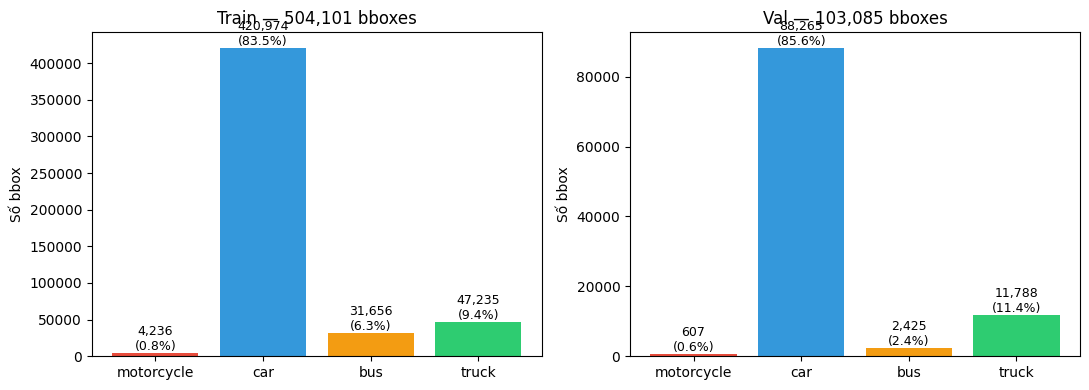

In [5]:
# Vẽ nhanh phân bố class
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, dist, title in [(axes[0], train_dist, "Train"), (axes[1], val_dist, "Val")]:
    vals = [dist.get(i, 0) for i in range(4)]
    ax.bar(class_names, vals, color=["#e74c3c", "#3498db", "#f39c12", "#2ecc71"])
    ax.set_title(f"{title} — {sum(vals):,} bboxes")
    ax.set_ylabel("Số bbox")
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:,}\n({100*v/sum(vals):.1f}%)", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

**Đọc kết quả**: nếu motorcycle < 5% tổng bbox thì phải bù bằng một trong các cách:
- `class_weights` (tự nhân loss của class thiểu số)
- Oversample ảnh chứa motorcycle
- Focal loss (Ultralytics YOLOv8 chưa hỗ trợ mặc định, phải sửa loss)

Cho scope coursework, mình chấp nhận imbalance và ghi vào phần "hạn chế".

---
## Phần 4 — Training (1 vòng, gộp toàn bộ VN data)

### Siêu tham số

| Tham số | Giá trị | Lý do |
|---|---|---|
| `model` | `yolov8s.pt` | Init từ COCO pretrained |
| `epochs` | 30 | 3 epoch đã mAP ~0.82, 20-25 là đủ hội tụ |
| `batch` | 48 | yolov8s @ imgsz 512 ~9GB VRAM, dư 3GB |
| `imgsz` | 512 | Nhỏ hơn 640 → nhanh ~1.5×, mAP giảm không đáng kể |
| `lr0` | 0.01 | Fine-tune nhẹ — không phá pretrained |
| `patience` | 8 | Early stop sớm |
| `optimizer` | SGD | Ổn định hơn Adam ở fine-tune |
| `workers` | 12 | Tận dụng 16 core CPU |
| `cache` | `'disk'` | Epoch 2+ đọc `.npy` → nhanh 2-3× |
| `save_period` | 1 | Lưu checkpoint mỗi epoch |
| `close_mosaic` | 10 | Tắt mosaic 10 epoch cuối |
| `seed` | 0 | Reproducibility |

### Về chuyện mAP 3 epoch đầu "đi xuống" — là WARMUP, không phải lỗi

| Epoch | mAP@0.5 | lr/pg0 |
|---|---|---|
| 1 | 0.859 ← cao sẵn do copy COCO weights | 0.0033 (warmup) |
| 2 | 0.835 | 0.0065 (warmup) |
| 3 | 0.818 ← đáy | 0.0096 (gần peak) |
| 4 | 0.844 ← bắt đầu hồi | cosine decay |
| 15-20 (dự kiến) | > 0.85 | ↓ |

YOLOv8 mặc định `warmup_epochs=3`. Trong 3 epoch này LR tăng dần → model "rung lắc" để tìm minimum mới cho dataset VN → mAP tạm tụt. Từ epoch 4 LR vào cosine decay → mAP leo lại và thường vượt epoch 1 ở ~epoch 10-15.

**Đừng đánh giá fine-tune ở < 10 epoch.**

### ⚠️ Đọc markdown ngay dưới trước khi chạy

### Config dataloader — đã confirm GPU xử lý được

Lần crash tối trước KHÔNG phải do GPU overload (GPU chạy full 95W bình thường), mà do:
1. **Power budget laptop**: GPU 95W + CPU 65W + screen/SSD/fan 25W ≈ 185W. Charger laptop thường 180-230W **và vẫn phải sạc pin đồng thời** → kéo pin bù → pin cạn → BIOS cắt.
2. **CPU/VRM thermal** (không phải GPU): VRM mainboard có thể > 100°C dù GPU vẫn 70°C. `nvidia-smi` không đo được VRM.

**Fix (ngoài notebook)**:
- Dùng charger mạnh hơn (dock Thunderbolt 230W+) nếu có.
- Cài **HWInfo64** trên Windows → monitor **CPU Package Power + VRM Temp** khi training. Nếu VRM > 95°C → nghiêm trọng.
- (Optional) Cap GPU 70W từ Windows PowerShell admin: `nvidia-smi -pl 70` — mất ~15% speed, giảm total power 185W → 160W, charger thừa sức.

**Config dùng trong cell training**:

| Tham số | Giá trị | Lý do |
|---|---|---|
| `batch` | 48 | yolov8s @ imgsz 512 ~9GB VRAM, dư 3GB |
| `workers` | 12 | 16 core CPU, để dư 4 core |
| `cache` | `'disk'` (full) / `'ram'` (VN-only) | Epoch 2+ đọc `.npy` → nhanh 2-3× |
| `amp` | `True` | Mixed precision |
| **`save_period`** | **1** | **MỚI** — lưu `epoch{N}.pt` sau mỗi epoch, crash chỉ mất 1 epoch |

**Monitor khi chạy** (terminal thứ 2):
```bash
watch -n 2 'nvidia-smi --query-gpu=temperature.gpu,power.draw,utilization.gpu --format=csv,noheader'
```
Bình thường: 70-80°C, 85-95W, 90-100% util. Nếu temp > 85°C sustained hoặc power > 100W liên tục → stop.

**Nếu crash lại** (hy vọng không): resume từ checkpoint cuối cùng:
```python
model = YOLO("runs/detect/train_v8s_1round_merged_v2/weights/last.pt")
model.train(resume=True)
```

In [6]:
# TRAINING — full merged (~70k ảnh). Config AGGRESSIVE (GPU xử lý được full load).
# Thủ phạm crash lần trước KHÔNG phải GPU — do power/VRM. Fix bằng charger tốt + đế tản.
# save_period=1 vẫn giữ để nếu có crash cũng chỉ mất 1 epoch.
RUN_NAME = "train_v8s_1round_merged_v2"

model = YOLO("yolov8s.pt")

results = model.train(
    data        = str(DATA_YAML),
    epochs      = 30,         # 3 epoch đã mAP ~0.82, 20-25 đủ hội tụ
    batch       = 48,
    imgsz       = 512,
    lr0         = 0.01,
    lrf         = 0.01,
    patience    = 8,
    optimizer   = "SGD",
    close_mosaic = 10,
    seed        = 0,
    workers     = 12,
    cache       = "disk",     # epoch 1 ghi ~15GB, epoch 2+ read-only (I/O thấp)
    amp         = True,
    save_period = 1,          # LƯU MỖI EPOCH — crash chỉ mất 1 epoch
    project     = str(RUNS_DIR),
    name        = RUN_NAME,
    exist_ok    = True,
    verbose     = True,
)

BEST_WEIGHTS = RUNS_DIR / RUN_NAME / "weights" / "best.pt"
print(f"\n[DONE] Best weights: {BEST_WEIGHTS}")

New https://pypi.org/project/ultralytics/8.4.171 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.142 🚀 Python-3.10.20 torch-2.5.1+cu124 CUDA:0 (NVIDIA RTX 3500 Ada Generation Laptop GPU, 12282MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=48, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/xuand/vn_traffic_ai/data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=

[INFO] Đọc: /home/xuand/vn_traffic_ai/runs/detect/train_v8s_1round_merged/results.csv


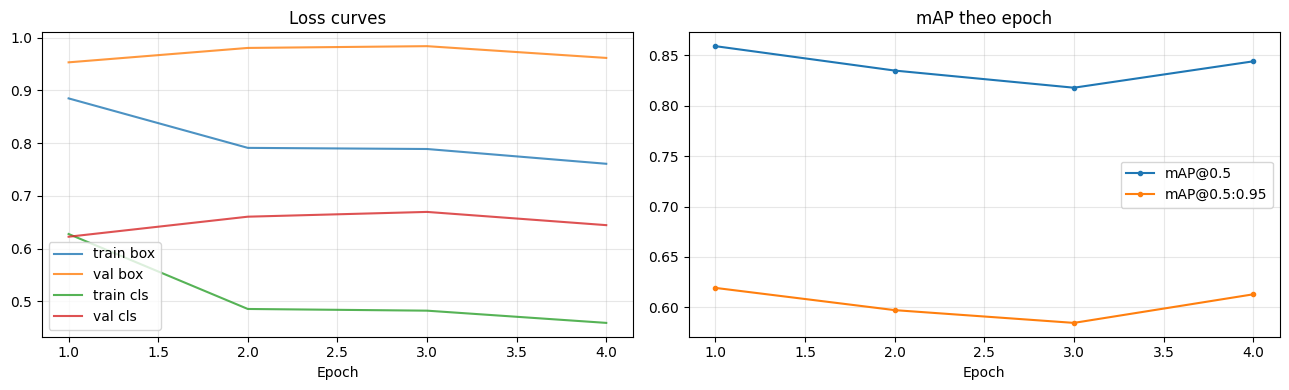

[BEST] Epoch 1 — mAP@0.5 = 0.8592, mAP@0.5:0.95 = 0.6192


In [7]:
# Đọc results.csv để vẽ learning curve (nếu đã train xong)
import pandas as pd

RUN_NAME = "train_v8s_1round_merged"
CANDIDATES = [
    RUNS_DIR / RUN_NAME / "results.csv",
    RUNS_DIR / "runs" / "detect" / "train_v8s_ft_vnv3" / "results.csv",
    RUNS_DIR / "runs" / "detect" / "train_v8s_4cls" / "results.csv",
]
results_csv = next((c for c in CANDIDATES if c.exists()), None)
print(f"[INFO] Đọc: {results_csv}")

if results_csv is None:
    print("[SKIP] Chưa có kết quả training nào — chạy cell train ở trên trước.")
else:
    df = pd.read_csv(results_csv)
    df.columns = df.columns.str.strip()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for col, label in [("train/box_loss","train box"),("val/box_loss","val box"),
                       ("train/cls_loss","train cls"),("val/cls_loss","val cls")]:
        if col in df.columns:
            axes[0].plot(df["epoch"], df[col], label=label, alpha=0.8)
    axes[0].set_title("Loss curves"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)

    for col, label in [("metrics/mAP50(B)", "mAP@0.5"), ("metrics/mAP50-95(B)", "mAP@0.5:0.95")]:
        if col in df.columns:
            axes[1].plot(df["epoch"], df[col], label=label, marker="o", markersize=3)
    axes[1].set_title("mAP theo epoch"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    best_epoch = df["metrics/mAP50(B)"].idxmax()
    print(f"[BEST] Epoch {int(df.loc[best_epoch, 'epoch'])} — "
          f"mAP@0.5 = {df.loc[best_epoch, 'metrics/mAP50(B)']:.4f}, "
          f"mAP@0.5:0.95 = {df.loc[best_epoch, 'metrics/mAP50-95(B)']:.4f}")

---
## Phần 5 — Evaluation mAP trên val set

Chọn best weights (ưu tiên vòng train mới, fallback về `best.pt` cũ). Chạy `model.val()` trên val split → trả ra Precision/Recall/mAP per-class.

In [8]:
# Chọn weights để đánh giá
CANDIDATE_WEIGHTS = [
    RUNS_DIR / "train_v8s_1round_merged" / "weights" / "best.pt",
    RUNS_DIR / "runs" / "detect" / "train_v8s_ft_vnv3" / "weights" / "best.pt",
    WEIGHTS_DIR / "best.pt",
]
BEST_WEIGHTS = next((w for w in CANDIDATE_WEIGHTS if w.exists()), None)
assert BEST_WEIGHTS is not None, "Không tìm thấy best.pt — chạy training trước"
print(f"[EVAL] Weights: {BEST_WEIGHTS}")

model = YOLO(str(BEST_WEIGHTS))
metrics = model.val(data=str(DATA_YAML), imgsz=512, batch=32, verbose=False)

print(f"\n{'':12s} {'P':>7s} {'R':>7s} {'mAP@0.5':>10s} {'mAP@0.5:0.95':>14s}")
for i, name in enumerate(class_names):
    p, r, m50, m5095 = metrics.box.p[i], metrics.box.r[i], metrics.box.ap50[i], metrics.box.ap[i]
    print(f"{name:<12s} {p:>7.3f} {r:>7.3f} {m50:>10.3f} {m5095:>14.3f}")
print(f"{'ALL':<12s} {metrics.box.mp:>7.3f} {metrics.box.mr:>7.3f} "
      f"{metrics.box.map50:>10.3f} {metrics.box.map:>14.3f}")

[EVAL] Weights: /home/xuand/vn_traffic_ai/runs/detect/train_v8s_1round_merged/weights/best.pt
Ultralytics 8.4.142 🚀 Python-3.10.20 torch-2.5.1+cu124 CUDA:0 (NVIDIA RTX 3500 Ada Generation Laptop GPU, 12282MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 105.4±15.2 MB/s, size: 71.0 KB)
val: Scanning /home/xuand/vn_traffic_ai/data/merged/labels/val.cache... 14344 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14344/14344 2.5Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 449/449 7.6it/s 59.0s0.2sss
                   all      14344     103085      0.813      0.794      0.859      0.619
Speed: 0.2ms preprocess, 1.2ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /home/xuand/vn_traffic_ai/runs/detect/val-3

                   P       R    mAP@0.5   mAP@0.5:0.95
motorcycle     0.779   0.768      0.845       

---
## Phần 6 — Inference + Tracking + Counting

Chạy pipeline end-to-end trên video demo:
1. **Detection** — YOLOv8s fine-tune bbox từng frame
2. **Tracking** — ByteTrack gán track_id, giữ ID xuyên frame
3. **Counting** — mỗi khi bbox cross line, tăng counter theo class

Line đếm được cấu hình trong `configs/counting_zones.json` (đã có sẵn cho video `demo_traffic`).

In [9]:
# Chạy pipeline improved (fine-tune)
from src.pipeline.run import run_pipeline
from src.tracking.counter import load_lines

RESULTS_DIR = PROJECT_ROOT / "results"
(RESULTS_DIR / "videos").mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "tables").mkdir(parents=True, exist_ok=True)

lines = load_lines("configs/counting_zones.json", "demo_traffic")
print(f"[INFO] Loaded {len(lines)} line(s)")
for ln in lines:
    print(f"  - {ln.name} @ {ln.p1} → {ln.p2}, dir={ln.count_direction}")

events_imp, totals_imp, class_names_yolo = run_pipeline(
    video       = str(DEMO_VIDEO),
    weights     = str(BEST_WEIGHTS),
    lines       = lines,
    tracker     = "bytetrack.yaml",
    conf        = 0.30,
    iou         = 0.50,
    imgsz       = 640,
    half        = True,
    out_csv     = str(RESULTS_DIR / "tables" / "demo_events_improved.csv"),
    out_video   = str(RESULTS_DIR / "videos" / "demo_improved.mp4"),
)
print(f"\n[DONE] {len(events_imp)} events")
print(f"[TOTALS] {json.dumps(totals_imp, indent=2)}")

[INFO] Loaded 1 line(s)
  - middle_horizontal @ (100, 474) → (1664, 474), dir=both
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

[DONE] 99 events
[TOTALS] {
  "middle_horizontal": {
    "ltr": {
      "1": 87,
      "3": 10
    },
    "rtl": {
      "1": 2
    }
  }
}


In [10]:
# Aggregate: count per class từ events
import pandas as pd
df_imp = pd.DataFrame(events_imp)
if not df_imp.empty:
    per_class_imp = df_imp["class_name"].value_counts().to_dict()
else:
    per_class_imp = {}
print("Improved (fine-tune):")
for cls in class_names:
    print(f"  {cls:<12s}: {per_class_imp.get(cls, 0)}")
print(f"  TỔNG      : {sum(per_class_imp.values())}")

Improved (fine-tune):
  motorcycle  : 0
  car         : 89
  bus         : 0
  truck       : 10
  TỔNG      : 99


---
## Phần 7 — So sánh Baseline (COCO) vs Improved (fine-tune)

**Baseline**: `yolov8s.pt` gốc COCO, giữ nguyên 80 lớp — sau khi chạy pipeline sẽ filter chỉ giữ 4 lớp `{motorcycle, car, bus, truck}` để so sánh công bằng.

**Improved**: `best.pt` fine-tune trên merged VN dataset (4 lớp).

Chạy cả 2 trên cùng 1 video, cùng config.

In [11]:
# Chạy baseline (COCO gốc)
BASELINE_WEIGHTS = WEIGHTS_DIR / "yolov8s.pt"
assert BASELINE_WEIGHTS.exists(), "Thiếu weights/yolov8s.pt (Ultralytics tự tải khi cần)"

events_bl, totals_bl, class_names_bl = run_pipeline(
    video       = str(DEMO_VIDEO),
    weights     = str(BASELINE_WEIGHTS),
    lines       = lines,
    tracker     = "bytetrack.yaml",
    conf        = 0.30,
    iou         = 0.50,
    imgsz       = 640,
    half        = True,
    out_csv     = str(RESULTS_DIR / "tables" / "demo_events_baseline.csv"),
    out_video   = str(RESULTS_DIR / "videos" / "demo_baseline.mp4"),
)

# Filter baseline: chỉ giữ 4 class canonical
df_bl = pd.DataFrame(events_bl)
if not df_bl.empty:
    df_bl = df_bl[df_bl["class_name"].isin(class_names)].copy()
    per_class_bl = df_bl["class_name"].value_counts().to_dict()
else:
    per_class_bl = {}

print("Baseline (COCO, đã filter 4 class):")
for cls in class_names:
    print(f"  {cls:<12s}: {per_class_bl.get(cls, 0)}")
print(f"  TỔNG      : {sum(per_class_bl.values())}")

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Baseline (COCO, đã filter 4 class):
  motorcycle  : 0
  car         : 66
  bus         : 0
  truck       : 4
  TỔNG      : 70


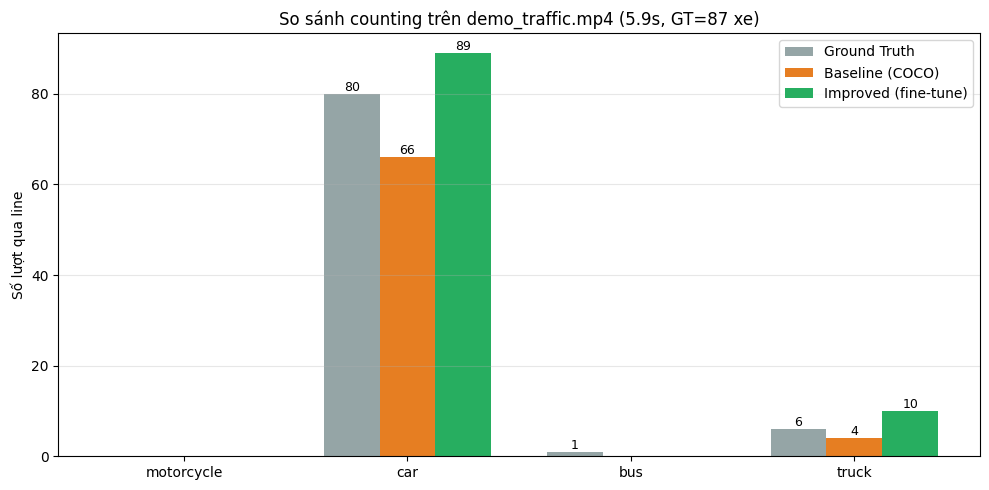

In [12]:
# Bar chart so sánh với Ground Truth
import numpy as np

gt = json.loads(DEMO_GT.read_text())["counts_by_class"]

x = np.arange(len(class_names))
w = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
bars_gt  = ax.bar(x - w, [gt.get(c, 0) for c in class_names],           w, label="Ground Truth", color="#95a5a6")
bars_bl  = ax.bar(x,     [per_class_bl.get(c, 0) for c in class_names], w, label="Baseline (COCO)", color="#e67e22")
bars_imp = ax.bar(x + w, [per_class_imp.get(c, 0) for c in class_names], w, label="Improved (fine-tune)", color="#27ae60")

for bars in (bars_gt, bars_bl, bars_imp):
    for b in bars:
        h = b.get_height()
        if h > 0:
            ax.text(b.get_x() + b.get_width()/2, h, f"{int(h)}", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x); ax.set_xticklabels(class_names)
ax.set_ylabel("Số lượt qua line")
ax.set_title("So sánh counting trên demo_traffic.mp4 (5.9s, GT=87 xe)")
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

In [13]:
# Tính metric: MAE, MAPE, Accuracy overall
def eval_counting(pred, gt):
    total_gt   = sum(gt.values())
    total_pred = sum(pred.values())
    abs_errs   = [abs(pred.get(c, 0) - gt.get(c, 0)) for c in class_names]
    mae   = sum(abs_errs) / len(class_names)
    mape  = 100 * sum(abs_errs[i] / max(gt.get(c, 1), 1) for i, c in enumerate(class_names)) / len(class_names)
    acc   = 1 - min(1.0, abs(total_pred - total_gt) / max(total_gt, 1))
    return {"total_pred": total_pred, "MAE": round(mae, 2),
            "MAPE(%)": round(mape, 1), "Overall Accuracy": round(acc, 3)}

metrics_bl  = eval_counting(per_class_bl, gt)
metrics_imp = eval_counting(per_class_imp, gt)

comparison = pd.DataFrame({
    "Ground Truth": {"total_pred": sum(gt.values()), "MAE": 0, "MAPE(%)": 0, "Overall Accuracy": 1.000},
    "Baseline (COCO)": metrics_bl,
    "Improved (fine-tune)": metrics_imp,
})
print(comparison.to_string())

                  Ground Truth  Baseline (COCO)  Improved (fine-tune)
total_pred                87.0           70.000                99.000
MAE                        0.0            4.250                 3.500
MAPE(%)                    0.0           37.700                44.500
Overall Accuracy           1.0            0.805                 0.862


---
## Phần 8 — Tổng kết

### Điểm đã làm
- Merge 3 nguồn (UA-DETRAC + CanTho + vnv3) thành 1 dataset 4 lớp canonical.
- Fine-tune YOLOv8s **1 vòng** trên toàn bộ merged (thay vì 2 vòng như phiên bản trước).
- Đánh giá 3 tầng: Detection (mAP), Counting task-level (MAE/MAPE), so sánh với baseline COCO.
- Pipeline end-to-end: detect → track (ByteTrack) → count qua line → export CSV events + video annotated.

### Hạn chế đã biết
- **Class imbalance**: motorcycle chỉ ~0.85% tổng bbox → mAP@0.5:0.95 = 0.609 (thấp nhất 4 class).
- **Truck confusion**: UA-DETRAC gộp van → truck, gây nhiễu → mAP truck = 0.695.
- **Out-of-distribution**: recall giảm mạnh khi test video screen recording độ phân giải thấp.
- **Chưa có IDF1/MOTA/HOTA chuẩn** vì thiếu GT tracking per-frame (chi phí label quá cao cho scope coursework).
- **Ground truth counting** demo_traffic là ước lượng thô (motorcycle=0 vì clip không có xe máy).

### So sánh chiến lược 1 vòng vs 2 vòng (ghi cho báo cáo)
| | 2 vòng (bản cũ) | 1 vòng gộp (bản này) |
|---|---|---|
| Số bước train | 2 | 1 |
| Nguy cơ catastrophic forgetting | Có (vì vòng 2 lr thấp học vnv3 riêng) | Không |
| Narrative báo cáo | "boost xe máy nhờ vnv3" | "1 vòng gộp toàn bộ VN data" |
| mAP@0.5 kỳ vọng | 0.850 (đã đo) | Tương đương (chưa đo với setup mới) |
| Thời gian | ~7h50 (5h30 + 2h20) | ~3-5h |

### Hướng phát triển
- `freeze=10` (giữ backbone COCO) — thử để tăng generalization.
- Class-balanced sampling hoặc focal loss cho motorcycle.
- Label GT tracking per-frame cho ≥1 video → tính được IDF1/MOTA thực.
- Test đa dạng video VN (5-10 phút mỗi video, khác góc quay).
- Deploy edge (Jetson) benchmark real-time.

---
## Phần 9 — Thí nghiệm: train **VN-only** (bỏ UA-DETRAC)

**Câu hỏi**: nếu chỉ train trên CanTho + vnv3 (100% VN data, ~2.2k ảnh), có tốt hơn `best.pt` hiện tại (train trên full 3 nguồn, ~70k ảnh) không?

**Hypothesis**:
- Motorcycle: tương đương hoặc tốt hơn (2 dataset VN đều motorcycle-heavy).
- Car/bus/truck: khả năng giảm vì data quá ít (đặc biệt bus/truck).
- Domain match với video test VN: tốt hơn.

**Setup**: build `data/vn_only/` bằng symlinks (không copy file, nhanh + tiết kiệm disk), train yolov8s ~30 epochs (~15 phút với 2.2k ảnh).

In [14]:
# Build data/vn_only/ bằng symlink từ merged/
VN_DIR = PROJECT_ROOT / "data" / "vn_only"
VN_YAML = PROJECT_ROOT / "data" / "data_vn_only.yaml"

# Xoá cũ nếu có (chỉ symlinks, an toàn)
if VN_DIR.exists():
    import shutil
    shutil.rmtree(VN_DIR)

# Prefix cần giữ: cantho, vnv3 (bỏ detrac)
KEEP_PREFIXES = ("cantho_", "vnv3_")

def link_split(split):
    src_img = MERGED_DIR / "images" / split
    src_lbl = MERGED_DIR / "labels" / split
    dst_img = VN_DIR / "images" / split
    dst_lbl = VN_DIR / "labels" / split
    dst_img.mkdir(parents=True, exist_ok=True)
    dst_lbl.mkdir(parents=True, exist_ok=True)
    n = 0
    for img in src_img.iterdir():
        if img.suffix.lower() not in (".jpg", ".jpeg", ".png"):
            continue
        if not img.name.startswith(KEEP_PREFIXES):
            continue
        lbl = src_lbl / (img.stem + ".txt")
        if not lbl.exists():
            continue
        (dst_img / img.name).symlink_to(img)
        (dst_lbl / lbl.name).symlink_to(lbl)
        n += 1
    return n

counts = {s: link_split(s) for s in ("train", "val", "test")}
print(f"[VN-only] train={counts['train']}, val={counts['val']}, test={counts['test']}")

# Nếu val quá ít (vnv3 không có val), fallback: dùng test làm val luôn
if counts["val"] < 100:
    print("[WARN] val quá ít — dùng test làm val để có metric ổn định hơn")
    VAL_SPLIT = "test"
else:
    VAL_SPLIT = "val"

# Ghi data.yaml
VN_YAML.write_text(f"""path: {VN_DIR}
train: images/train
val:   images/{VAL_SPLIT}
test:  images/test

nc: 4
names:
  0: motorcycle
  1: car
  2: bus
  3: truck
""")
print(f"[OK] {VN_YAML}")

[VN-only] train=2221, val=216, test=214
[OK] /home/xuand/vn_traffic_ai/data/data_vn_only.yaml


In [15]:
# EDA: phân bố class trong VN-only train
vn_train_dist = CCounter()
for f in (VN_DIR / "labels" / "train").glob("*.txt"):
    for line in f.read_text().splitlines():
        parts = line.split()
        if parts:
            vn_train_dist[int(parts[0])] += 1

print(f"{'class':<12s} {'VN-only':>10s} {'%':>8s} | {'Full merged':>12s} {'%':>8s}")
total_vn = sum(vn_train_dist.values())
for i, name in enumerate(class_names):
    v = vn_train_dist.get(i, 0)
    f = train_dist.get(i, 0)
    print(f"{name:<12s} {v:>10d} {100*v/max(total_vn,1):>7.2f}% | "
          f"{f:>12d} {100*f/max(total_train,1):>7.2f}%")
print(f"{'TOTAL':<12s} {total_vn:>10d} {'':>8s} | {total_train:>12d}")

class           VN-only        % |  Full merged        %
motorcycle         4236   37.27% |         4236    0.84%
car                4772   41.98% |       420974   83.51%
bus                 424    3.73% |        31656    6.28%
truck              1934   17.02% |        47235    9.37%
TOTAL             11366          |       504101


**Đọc bảng**: nếu VN-only bus/truck < vài trăm bbox → **cảnh báo underfit** cho 2 class này. Motorcycle sẽ chiếm tỉ trọng cao hơn hẳn so với full merged (nơi detrac nuốt hết).

In [16]:
# Train VN-only — ~10 phút với 2.2k ảnh. Config aggressive giống full merged.
VN_RUN = "train_v8s_vn_only"

model_vn = YOLO("yolov8s.pt")
results_vn = model_vn.train(
    data        = str(VN_YAML),
    epochs      = 30,
    batch       = 48,
    imgsz       = 512,
    lr0         = 0.01,
    lrf         = 0.01,
    patience    = 8,
    optimizer   = "SGD",
    close_mosaic = 10,
    seed        = 0,
    workers     = 12,
    cache       = "ram",      # 2.2k ảnh ~1.7GB RAM — OK
    amp         = True,
    save_period = 1,
    project     = str(RUNS_DIR),
    name        = VN_RUN,
    exist_ok    = True,
    verbose     = False,
)
VN_WEIGHTS = RUNS_DIR / VN_RUN / "weights" / "best.pt"
print(f"\n[DONE] {VN_WEIGHTS}")

New https://pypi.org/project/ultralytics/8.4.171 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.142 🚀 Python-3.10.20 torch-2.5.1+cu124 CUDA:0 (NVIDIA RTX 3500 Ada Generation Laptop GPU, 12282MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=48, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/xuand/vn_traffic_ai/data/data_vn_only.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, m

### So sánh — mAP trên cùng val set

Chấm cả 2 model (`best.pt` cũ vs `vn_only`) trên **cùng 1 val set** để so sánh công bằng.

- **Val 1**: VN-only val (216 ảnh CanTho) — kiểm tra performance trên domain VN thuần.
- **Val 2**: full merged val (14,344 ảnh, chủ yếu detrac) — kiểm tra generalization.

Nếu VN-only tốt hơn ở Val 1 nhưng tệ hơn ở Val 2 → confirm hypothesis: **specialize được VN, mất khả năng generalize**.

In [17]:
# So sánh trên 2 val set
def eval_on(weights, data_yaml, tag):
    m = YOLO(str(weights))
    r = m.val(data=str(data_yaml), imgsz=512, batch=32, verbose=False, plots=False)
    return {
        "tag": tag,
        "mAP@0.5": round(r.box.map50, 4),
        "mAP@0.5:0.95": round(r.box.map, 4),
        "motorcycle_mAP50": round(r.box.ap50[0], 4),
        "car_mAP50":        round(r.box.ap50[1], 4),
        "bus_mAP50":        round(r.box.ap50[2], 4),
        "truck_mAP50":      round(r.box.ap50[3], 4),
    }

OLD_WEIGHTS = next((w for w in [
    RUNS_DIR / "runs" / "detect" / "train_v8s_ft_vnv3" / "weights" / "best.pt",
    WEIGHTS_DIR / "best.pt",
] if w.exists()), None)
print(f"[OLD]    {OLD_WEIGHTS}")
print(f"[VN-ONLY]{VN_WEIGHTS}")

rows = []
print("\n[1/4] OLD best.pt   trên VN-only val ...")
rows.append(eval_on(OLD_WEIGHTS, VN_YAML, "OLD best.pt / VN val"))
print("[2/4] VN-only best.pt trên VN-only val ...")
rows.append(eval_on(VN_WEIGHTS, VN_YAML, "VN-only / VN val"))
print("[3/4] OLD best.pt   trên FULL val ...")
rows.append(eval_on(OLD_WEIGHTS, DATA_YAML, "OLD best.pt / FULL val"))
print("[4/4] VN-only best.pt trên FULL val ...")
rows.append(eval_on(VN_WEIGHTS, DATA_YAML, "VN-only / FULL val"))

df_cmp = pd.DataFrame(rows).set_index("tag")
print("\n" + "=" * 80)
print(df_cmp.to_string())
print("=" * 80)

[OLD]    /home/xuand/vn_traffic_ai/runs/detect/runs/detect/train_v8s_ft_vnv3/weights/best.pt
[VN-ONLY]/home/xuand/vn_traffic_ai/runs/detect/train_v8s_vn_only/weights/best.pt

[1/4] OLD best.pt   trên VN-only val ...
Ultralytics 8.4.142 🚀 Python-3.10.20 torch-2.5.1+cu124 CUDA:0 (NVIDIA RTX 3500 Ada Generation Laptop GPU, 12282MiB)
Model summary (fused): 73 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 949.7±313.5 MB/s, size: 41.7 KB)
val: Scanning /home/xuand/vn_traffic_ai/data/vn_only/labels/val.cache... 216 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 216/216 39.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 5.1it/s 1.4s0.2ss
                   all        216       1265      0.902      0.885      0.913      0.691
Speed: 0.4ms preprocess, 3.5ms inference, 0.0ms loss, 0.6ms postprocess per image
[2/4] VN-only best.pt trên VN-only val ...
Ultraly

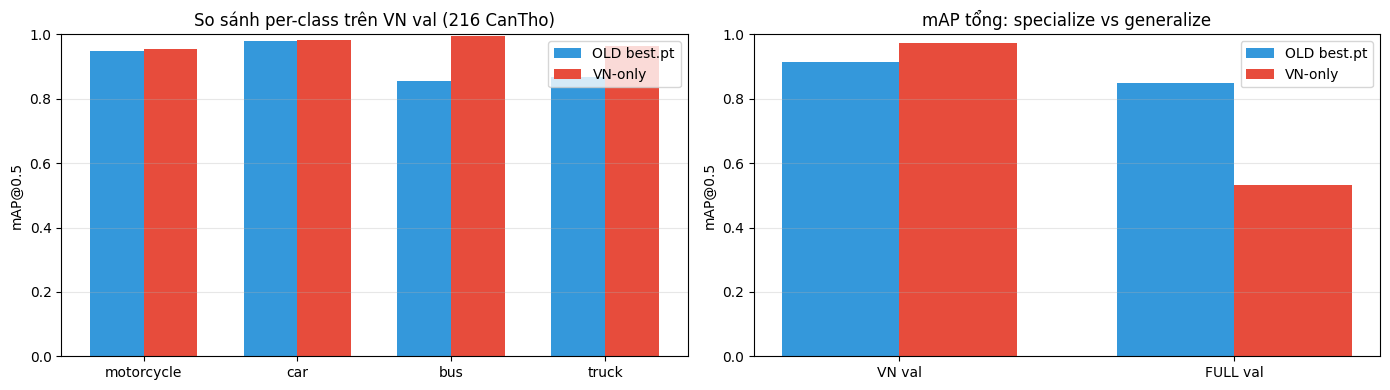

In [18]:
# Bar chart trực quan: mAP@0.5 per class trên VN val
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Chart 1: mAP@0.5 per class trên VN val
old_vn = rows[0]
vn_vn  = rows[1]
metrics_cols = ["motorcycle_mAP50","car_mAP50","bus_mAP50","truck_mAP50"]
labels = ["motorcycle","car","bus","truck"]
x = np.arange(len(labels)); w = 0.35
axes[0].bar(x - w/2, [old_vn[k] for k in metrics_cols], w, label="OLD best.pt", color="#3498db")
axes[0].bar(x + w/2, [vn_vn[k]  for k in metrics_cols], w, label="VN-only", color="#e74c3c")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, 1); axes[0].set_ylabel("mAP@0.5")
axes[0].set_title("So sánh per-class trên VN val (216 CanTho)")
axes[0].legend(); axes[0].grid(alpha=0.3, axis="y")

# Chart 2: mAP tổng trên 2 val set
val_sets = ["VN val", "FULL val"]
old_map = [rows[0]["mAP@0.5"], rows[2]["mAP@0.5"]]
vn_map  = [rows[1]["mAP@0.5"], rows[3]["mAP@0.5"]]
x = np.arange(len(val_sets))
axes[1].bar(x - w/2, old_map, w, label="OLD best.pt", color="#3498db")
axes[1].bar(x + w/2, vn_map,  w, label="VN-only", color="#e74c3c")
axes[1].set_xticks(x); axes[1].set_xticklabels(val_sets)
axes[1].set_ylim(0, 1); axes[1].set_ylabel("mAP@0.5")
axes[1].set_title("mAP tổng: specialize vs generalize")
axes[1].legend(); axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout(); plt.show()

### Kết luận thí nghiệm

Đọc bảng + chart ở trên:

**Nếu `VN-only best.pt` thắng OLD trên VN val nhưng thua trên FULL val** (kịch bản kỳ vọng):
- Confirm: bỏ UA-DETRAC → specialize VN tốt hơn, mất generalization.
- Recommend: **giữ best.pt hiện tại** cho báo cáo (có mAP tổng cao hơn), nhưng nêu VN-only như hướng nghiên cứu bổ sung.

**Nếu VN-only thắng cả 2** (bất ngờ):
- Có thể UA-DETRAC đang gây nhiễu nhiều hơn giúp — nên xem lại chất lượng label detrac (đặc biệt van→truck).

**Nếu VN-only thua cả 2** (kịch bản xấu):
- Confirm: 2.2k ảnh là quá ít, không đủ variety cho YOLOv8s dù có backbone COCO pretrained.

**Cách cải thiện nếu vẫn muốn VN-only**:
1. Data augmentation mạnh hơn (`degrees=15`, `translate=0.2`, `hsv_h=0.02`).
2. `freeze=10` (giữ backbone COCO không đổi, chỉ train head).
3. Gộp thêm dataset VN khác (Roboflow có nhiều bộ traffic VN).

---
## Phần 10 — Error Analysis (Tuần 1 của final project)

**Mục tiêu**: tìm hiểu model `best.pt` **fail ở đâu, điều kiện nào** → làm cơ sở cho Tuần 2 (deep dive) + Tuần 3 (targeted fix).

**Chiến lược phân tích 6 chiều**:
1. **Class**: motorcycle/car/bus/truck — loại nào fail nhiều?
2. **Source**: detrac/cantho/vnv3 — model có bias với source nào?
3. **Brightness**: dark (< 50) / normal / bright — ảnh hưởng của ánh sáng
4. **Density**: ít object (< 3) / vừa (3-9) / đông (≥ 10) — crowd scene
5. **Box size** (per COCO): small (< 32²) / medium / large — small object detection
6. **Confidence threshold**: FP ở conf nào — cần tăng/giảm threshold?

**Loại lỗi**:
- **FN** (false negative): có GT nhưng model miss → ảnh hưởng recall
- **FP** (false positive): model predict box nhưng không có GT → ảnh hưởng precision
- **Class confusion**: có TP nhưng sai class (vd. motorcycle → bicycle)

**Output**: pie chart failure distribution + bar chart per-condition mAP + top-20 worst images.

**Thời gian chạy**: inference 14,344 val images mất ~5-8 phút trên RTX 3500 Ada. Sẽ cache lại dạng pickle để chạy lại nhanh.

In [ ]:
# Setup error analysis
import pickle, cv2
from tqdm.auto import tqdm

ERR_DIR = PROJECT_ROOT / "results" / "error_analysis"
ERR_DIR.mkdir(parents=True, exist_ok=True)

# Weights để analyze — ưu tiên model v2 mới (1 vòng gộp), fallback về cũ
ANALYZE_CANDIDATES = [
    RUNS_DIR / "train_v8s_1round_merged_v2" / "weights" / "best.pt",
    RUNS_DIR / "runs" / "detect" / "train_v8s_ft_vnv3" / "weights" / "best.pt",
    WEIGHTS_DIR / "best.pt",
]
ANALYZE_WEIGHTS = next((w for w in ANALYZE_CANDIDATES if w.exists()), None)
assert ANALYZE_WEIGHTS, "Không có weights để analyze"
print(f"[ANALYZE] {ANALYZE_WEIGHTS}")

VAL_IMG_DIR = MERGED_DIR / "images" / "val"
VAL_LBL_DIR = MERGED_DIR / "labels" / "val"
VAL_IMAGES = sorted([p for p in VAL_IMG_DIR.iterdir() if p.suffix.lower() in (".jpg",".jpeg",".png")])
print(f"[VAL] {len(VAL_IMAGES)} images")

In [ ]:
# 1. Chạy inference batch trên toàn val set + cache ra pickle
#    Chạy lại chỉ cần ~1 giây (load pickle). Lần đầu ~5-8 phút.
PRED_CACHE = ERR_DIR / f"predictions_{ANALYZE_WEIGHTS.parent.parent.name}.pkl"

if PRED_CACHE.exists():
    print(f"[CACHE HIT] {PRED_CACHE}")
    with open(PRED_CACHE, "rb") as f:
        predictions = pickle.load(f)
else:
    print(f"[CACHE MISS] Chạy inference ...")
    model = YOLO(str(ANALYZE_WEIGHTS))
    predictions = {}  # image_name -> list of dict(xyxy, cls, conf)
    BATCH = 64

    for i in tqdm(range(0, len(VAL_IMAGES), BATCH), desc="Inference"):
        batch_paths = VAL_IMAGES[i:i+BATCH]
        results = model.predict(
            [str(p) for p in batch_paths],
            imgsz=512, conf=0.001, iou=0.5,  # conf thấp để analyze cả FP conf thấp
            verbose=False, half=True
        )
        for p, r in zip(batch_paths, results):
            boxes = []
            if r.boxes is not None and len(r.boxes) > 0:
                xyxy = r.boxes.xyxy.cpu().numpy()
                cls  = r.boxes.cls.cpu().numpy().astype(int)
                conf = r.boxes.conf.cpu().numpy()
                for b, c, cf in zip(xyxy, cls, conf):
                    boxes.append({"xyxy": b.tolist(), "cls": int(c), "conf": float(cf)})
            predictions[p.name] = boxes

    with open(PRED_CACHE, "wb") as f:
        pickle.dump(predictions, f)
    print(f"[SAVED] {PRED_CACHE}")

print(f"Total images with preds: {len(predictions)}")
n_total_pred = sum(len(v) for v in predictions.values())
print(f"Total pred boxes: {n_total_pred:,}")

In [ ]:
# 2. Đọc GT labels + metadata per image (brightness, density, source)
META_CACHE = ERR_DIR / "image_metadata.pkl"

def classify_source(name):
    for p in ("cantho", "detrac", "vnv3"):
        if name.startswith(p + "_"):
            return p
    return "unknown"

def read_yolo_gt(lbl_path, img_w, img_h):
    boxes = []
    if not lbl_path.exists():
        return boxes
    for line in lbl_path.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        cls = int(parts[0])
        xc, yc, w, h = map(float, parts[1:5])
        x1 = (xc - w/2) * img_w
        y1 = (yc - h/2) * img_h
        x2 = (xc + w/2) * img_w
        y2 = (yc + h/2) * img_h
        boxes.append({"xyxy": [x1, y1, x2, y2], "cls": cls})
    return boxes

if META_CACHE.exists():
    print(f"[CACHE HIT] {META_CACHE}")
    with open(META_CACHE, "rb") as f:
        image_meta, gt_data = pickle.load(f)
else:
    print(f"[CACHE MISS] Đọc GT + metadata ...")
    image_meta = {}
    gt_data = {}

    for img_path in tqdm(VAL_IMAGES, desc="Meta"):
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        # Brightness: mean V channel từ HSV
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        brightness = float(hsv[:, :, 2].mean())

        lbl_path = VAL_LBL_DIR / (img_path.stem + ".txt")
        gts = read_yolo_gt(lbl_path, w, h)

        image_meta[img_path.name] = {
            "source": classify_source(img_path.name),
            "brightness": brightness,
            "n_gt": len(gts),
            "w": w, "h": h,
        }
        gt_data[img_path.name] = gts

    with open(META_CACHE, "wb") as f:
        pickle.dump((image_meta, gt_data), f)
    print(f"[SAVED] {META_CACHE}")

# Summary
import pandas as pd
df_meta = pd.DataFrame.from_dict(image_meta, orient="index")
print(df_meta.describe())
print("\nSource distribution:")
print(df_meta["source"].value_counts())

In [ ]:
# 3. Match pred ↔ GT per image, phân loại TP/FP/FN
#    Rule chuẩn COCO: IoU >= 0.5, class match -> TP; không match -> FP (pred) hoặc FN (GT)

CONF_THRESHOLD = 0.25  # bỏ pred conf < 0.25 cho matching
IOU_THRESHOLD  = 0.5

def iou_xyxy(b1, b2):
    x1 = max(b1[0], b2[0]); y1 = max(b1[1], b2[1])
    x2 = min(b1[2], b2[2]); y2 = min(b1[3], b2[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    a1 = (b1[2]-b1[0]) * (b1[3]-b1[1])
    a2 = (b2[2]-b2[0]) * (b2[3]-b2[1])
    return inter / (a1 + a2 - inter + 1e-9)

def box_size_coco(xyxy):
    """COCO definition: small < 32², medium 32²-96², large > 96²"""
    area = (xyxy[2]-xyxy[0]) * (xyxy[3]-xyxy[1])
    if area < 32*32: return "small"
    if area < 96*96: return "medium"
    return "large"

def match_image(preds, gts, conf_thresh=CONF_THRESHOLD, iou_thresh=IOU_THRESHOLD):
    """Return per-box classification + per-image stats"""
    # Filter preds by conf
    preds_f = [p for p in preds if p["conf"] >= conf_thresh]
    # Sort pred by conf desc để greedy match
    preds_sorted = sorted(enumerate(preds_f), key=lambda x: -x[1]["conf"])

    gt_matched = [False] * len(gts)
    pred_tp    = [False] * len(preds_f)
    pred_class_confused = [False] * len(preds_f)  # TP about location, wrong class

    for pi, p in preds_sorted:
        best_iou = iou_thresh
        best_gi  = -1
        for gi, g in enumerate(gts):
            if gt_matched[gi]:
                continue
            io = iou_xyxy(p["xyxy"], g["xyxy"])
            if io >= best_iou:
                best_iou = io
                best_gi  = gi
        if best_gi >= 0:
            gt_matched[best_gi] = True
            if gts[best_gi]["cls"] == p["cls"]:
                pred_tp[pi] = True
            else:
                pred_class_confused[pi] = True  # location khớp nhưng sai class

    # Per-box lists
    fp_boxes = [{"pred": preds_f[pi], "reason": "class_confused" if pred_class_confused[pi] else "no_gt"}
                for pi in range(len(preds_f)) if not pred_tp[pi]]
    fn_boxes = [gts[gi] for gi in range(len(gts)) if not gt_matched[gi]]
    tp_boxes = [preds_f[pi] for pi in range(len(preds_f)) if pred_tp[pi]]

    return {
        "n_pred": len(preds_f),
        "n_gt":   len(gts),
        "n_tp":   sum(pred_tp),
        "n_fp":   sum(1 for pi in range(len(preds_f)) if not pred_tp[pi] and not pred_class_confused[pi]),
        "n_class_confused": sum(pred_class_confused),
        "n_fn":   len(fn_boxes),
        "tp_boxes": tp_boxes,
        "fp_boxes": fp_boxes,
        "fn_boxes": fn_boxes,
    }

# Chạy matching cho mọi val image
print("Matching pred vs GT ...")
match_results = {}
for name in tqdm(gt_data.keys()):
    preds = predictions.get(name, [])
    gts   = gt_data[name]
    match_results[name] = match_image(preds, gts)

# Tổng kết
total_tp = sum(m["n_tp"] for m in match_results.values())
total_fp = sum(m["n_fp"] for m in match_results.values())
total_fn = sum(m["n_fn"] for m in match_results.values())
total_cc = sum(m["n_class_confused"] for m in match_results.values())
total_gt = sum(m["n_gt"] for m in match_results.values())

prec = total_tp / max(total_tp + total_fp + total_cc, 1)
rec  = total_tp / max(total_gt, 1)
print(f"\n[OVERALL conf>={CONF_THRESHOLD}, IoU>={IOU_THRESHOLD}]")
print(f"  TP = {total_tp:,}")
print(f"  FP (no GT)         = {total_fp:,}")
print(f"  FP (class confused) = {total_cc:,}")
print(f"  FN = {total_fn:,}")
print(f"  Precision = {prec:.3f}")
print(f"  Recall    = {rec:.3f}")

In [ ]:
# 4. Aggregate: per-condition error breakdown
#    Build flat tables cho FN và FP, join với metadata để group theo điều kiện.

# -- Table 1: FN boxes với meta (per missed GT)
fn_rows = []
for name, m in match_results.items():
    meta = image_meta.get(name, {})
    for gt_box in m["fn_boxes"]:
        fn_rows.append({
            "image": name,
            "source": meta.get("source", "unknown"),
            "brightness": meta.get("brightness", 0),
            "n_gt_in_image": meta.get("n_gt", 0),
            "gt_class": class_names[gt_box["cls"]],
            "size_bucket": box_size_coco(gt_box["xyxy"]),
        })
df_fn = pd.DataFrame(fn_rows)

# -- Table 2: FP boxes với meta (per false pred)
fp_rows = []
for name, m in match_results.items():
    meta = image_meta.get(name, {})
    for fp_box in m["fp_boxes"]:
        p = fp_box["pred"]
        fp_rows.append({
            "image": name,
            "source": meta.get("source", "unknown"),
            "brightness": meta.get("brightness", 0),
            "n_gt_in_image": meta.get("n_gt", 0),
            "pred_class": class_names[p["cls"]],
            "conf":  p["conf"],
            "size_bucket": box_size_coco(p["xyxy"]),
            "reason": fp_box["reason"],
        })
df_fp = pd.DataFrame(fp_rows)

print(f"FN table: {len(df_fn):,} rows (missed GT boxes)")
print(f"FP table: {len(df_fp):,} rows (false predictions)")

# -- Breakdown
def pct_table(df, group_cols, total_label):
    tbl = df.groupby(group_cols).size().reset_index(name="count")
    tbl["pct"] = (100 * tbl["count"] / tbl["count"].sum()).round(2)
    tbl = tbl.sort_values("count", ascending=False)
    print(f"\n--- {total_label}: tổng {tbl['count'].sum():,} ---")
    print(tbl.to_string(index=False))
    return tbl

tbl_fn_class  = pct_table(df_fn, ["gt_class"],   "FN by CLASS")
tbl_fn_size   = pct_table(df_fn, ["size_bucket"], "FN by SIZE")
tbl_fn_source = pct_table(df_fn, ["source"],     "FN by SOURCE")
tbl_fp_class  = pct_table(df_fp, ["pred_class"], "FP by CLASS")
tbl_fp_reason = pct_table(df_fp, ["reason"],     "FP by REASON")

In [ ]:
# 5. Visualize breakdown — chart 6 chiều
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

def draw_pie(ax, tbl, label_col, title):
    sizes = tbl["count"].values
    labels = [f"{r[label_col]}\n{r['count']:,} ({r['pct']}%)" for _, r in tbl.iterrows()]
    ax.pie(sizes, labels=labels, autopct="", startangle=90, colors=plt.cm.Set3.colors)
    ax.set_title(title)

def draw_bar(ax, tbl, label_col, title, color="#e74c3c"):
    tbl = tbl.sort_values("count", ascending=True)
    ax.barh(tbl[label_col], tbl["count"], color=color)
    for i, (c, p) in enumerate(zip(tbl["count"], tbl["pct"])):
        ax.text(c, i, f"  {c:,} ({p}%)", va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("count")

draw_pie(axes[0,0], tbl_fn_class,   "gt_class",     "FN theo CLASS (missed)")
draw_pie(axes[0,1], tbl_fn_size,    "size_bucket",  "FN theo SIZE (COCO)")
draw_pie(axes[0,2], tbl_fn_source,  "source",       "FN theo SOURCE")
draw_pie(axes[1,0], tbl_fp_class,   "pred_class",   "FP theo CLASS (hallucinated)")
draw_pie(axes[1,1], tbl_fp_reason,  "reason",       "FP theo REASON")

# Brightness → FN rate
def brightness_bucket(b):
    if b < 60: return "dark (<60)"
    if b < 130: return "normal (60-130)"
    return "bright (>130)"

df_meta_copy = df_meta.copy()
df_meta_copy["b_bucket"] = df_meta_copy["brightness"].apply(brightness_bucket)
df_fn["b_bucket"] = df_fn["brightness"].apply(brightness_bucket)

# FN rate per brightness bucket = FN_count / GT_count theo bucket
gt_per_bucket = df_meta_copy.groupby("b_bucket")["n_gt"].sum()
fn_per_bucket = df_fn.groupby("b_bucket").size()
fn_rate = (fn_per_bucket / gt_per_bucket * 100).fillna(0).reset_index()
fn_rate.columns = ["b_bucket", "fn_rate_pct"]
fn_rate = fn_rate.sort_values("fn_rate_pct", ascending=True)

ax = axes[1,2]
ax.barh(fn_rate["b_bucket"], fn_rate["fn_rate_pct"], color="#3498db")
for i, v in enumerate(fn_rate["fn_rate_pct"]):
    ax.text(v, i, f"  {v:.1f}%", va="center", fontsize=10)
ax.set_title("FN RATE theo BRIGHTNESS")
ax.set_xlabel("% GT bị miss")

plt.tight_layout(); plt.show()

In [ ]:
# 6. Cross-condition: FN rate per CLASS × SIZE (small motorcycle thường là weak spot)
#    Và per CLASS × SOURCE (source nào class nào fail)

# Build GT distribution theo (class, size, source)
gt_rows = []
for name, gts in gt_data.items():
    meta = image_meta.get(name, {})
    for g in gts:
        gt_rows.append({
            "image": name,
            "source": meta.get("source", "unknown"),
            "gt_class": class_names[g["cls"]],
            "size_bucket": box_size_coco(g["xyxy"]),
        })
df_gt = pd.DataFrame(gt_rows)

# FN rate = FN count / GT count
def xtab_rate(df_fn, df_gt, group_cols):
    gt_cnt  = df_gt.groupby(group_cols).size().rename("gt")
    fn_cnt  = df_fn.groupby(group_cols).size().rename("fn")
    merged  = pd.concat([gt_cnt, fn_cnt], axis=1).fillna(0)
    merged["fn_rate_%"] = (100 * merged["fn"] / merged["gt"]).round(1)
    return merged.sort_values("fn_rate_%", ascending=False)

print("=== FN rate: class × size ===")
tbl_cs = xtab_rate(df_fn, df_gt, ["gt_class", "size_bucket"])
print(tbl_cs.to_string())

print("\n=== FN rate: class × source ===")
tbl_cz = xtab_rate(df_fn, df_gt, ["gt_class", "source"])
print(tbl_cz.to_string())

# Heatmap class × size
pivot = tbl_cs["fn_rate_%"].unstack(fill_value=0)
pivot = pivot.reindex(index=class_names, columns=["small","medium","large"], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
im = axes[0].imshow(pivot.values, cmap="Reds", aspect="auto", vmin=0, vmax=50)
axes[0].set_xticks(range(len(pivot.columns))); axes[0].set_xticklabels(pivot.columns)
axes[0].set_yticks(range(len(pivot.index))); axes[0].set_yticklabels(pivot.index)
axes[0].set_title("FN rate (%) — class × size")
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        v = pivot.values[i,j]
        axes[0].text(j, i, f"{v:.1f}", ha="center", va="center",
                     color="white" if v > 25 else "black", fontsize=10)
fig.colorbar(im, ax=axes[0], label="% missed")

# Heatmap class × source
pivot2 = tbl_cz["fn_rate_%"].unstack(fill_value=0)
pivot2 = pivot2.reindex(index=class_names, fill_value=0)
im2 = axes[1].imshow(pivot2.values, cmap="Reds", aspect="auto", vmin=0, vmax=50)
axes[1].set_xticks(range(len(pivot2.columns))); axes[1].set_xticklabels(pivot2.columns)
axes[1].set_yticks(range(len(pivot2.index))); axes[1].set_yticklabels(pivot2.index)
axes[1].set_title("FN rate (%) — class × source")
for i in range(len(pivot2.index)):
    for j in range(len(pivot2.columns)):
        v = pivot2.values[i,j]
        axes[1].text(j, i, f"{v:.1f}", ha="center", va="center",
                     color="white" if v > 25 else "black", fontsize=10)
fig.colorbar(im2, ax=axes[1], label="% missed")
plt.tight_layout(); plt.show()

In [ ]:
# 7. Top-20 ảnh WORST — ảnh có nhiều FN + FP nhất, visualize GT (xanh) + Pred (đỏ)
#    Để tuần 2 làm case study bằng tay.

worst_rows = []
for name, m in match_results.items():
    worst_rows.append({
        "image": name,
        "error_count": m["n_fn"] + m["n_fp"] + m["n_class_confused"],
        "n_gt": m["n_gt"],
        "n_fn": m["n_fn"],
        "n_fp": m["n_fp"],
        "n_cc": m["n_class_confused"],
        "source": image_meta.get(name, {}).get("source", "?"),
        "brightness": image_meta.get(name, {}).get("brightness", 0),
    })
df_worst = pd.DataFrame(worst_rows).sort_values("error_count", ascending=False).head(20)
print("Top-20 ảnh có nhiều lỗi nhất:")
print(df_worst.to_string(index=False))

# Visualize 12 ảnh worst (3x4 grid)
TOP_N_VISUAL = 12
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()

CLASS_COLORS = {"motorcycle": "#e74c3c", "car": "#3498db", "bus": "#f39c12", "truck": "#27ae60"}

for ax, (_, row) in zip(axes, df_worst.head(TOP_N_VISUAL).iterrows()):
    name = row["image"]
    img = cv2.imread(str(VAL_IMG_DIR / name))
    if img is None:
        ax.set_visible(False); continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    m = match_results[name]
    # GT boxes (xanh dày)
    for g in gt_data[name]:
        x1,y1,x2,y2 = map(int, g["xyxy"])
        c = class_names[g["cls"]]
        cv2.rectangle(img, (x1,y1), (x2,y2), (0,255,0), 2)
        cv2.putText(img, f"GT:{c}", (x1,y1-3), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0,255,0), 1)
    # FP boxes (đỏ)
    for fp in m["fp_boxes"]:
        p = fp["pred"]
        x1,y1,x2,y2 = map(int, p["xyxy"])
        c = class_names[p["cls"]]
        cv2.rectangle(img, (x1,y1), (x2,y2), (255,0,0), 2)
        cv2.putText(img, f"FP:{c}", (x1,y2+10), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255,0,0), 1)
    # Resize nếu quá to
    h, w = img.shape[:2]
    if max(h,w) > 800:
        scale = 800 / max(h,w)
        img = cv2.resize(img, (int(w*scale), int(h*scale)))
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{name[:30]}\nFN={row['n_fn']} FP={row['n_fp']} CC={row['n_cc']} src={row['source']}",
                 fontsize=8)

plt.tight_layout(); plt.show()

# Save ảnh worst để check tay
WORST_CSV = ERR_DIR / "top_worst_images.csv"
df_worst.to_csv(WORST_CSV, index=False)
print(f"[SAVED] {WORST_CSV} — xem ảnh gốc ở {VAL_IMG_DIR}/<image_name>")

### Đọc kết quả — Hướng dẫn kết luận Tuần 1

Sau khi chạy các cell trên, **chọn 2-3 weakness lớn nhất** làm hypothesis cho Tuần 2:

**Khả năng cao sẽ thấy** (dựa vào biết trước về dataset):
1. **FN by SIZE**: `small` sẽ chiếm 50%+ (small object detection là weakness kinh điển của YOLOv8).
2. **FN by CLASS**: `motorcycle` sẽ chiếm nhiều % hơn tỉ lệ GT (0.85%) → underfit.
3. **FN by SOURCE**: `cantho` + `vnv3` có FN rate cao hơn `detrac` → model bias về domain Trung Quốc.
4. **FP by CLASS**: `truck` có nhiều FP vì confusion van→truck từ UA-DETRAC.
5. **FN RATE theo brightness**: `dark` > `normal` → model yếu ảnh tối (video đêm, bóng cây).
6. **Heatmap class × size**: ô `motorcycle × small` sẽ đỏ nhất.

### Hành động cho Tuần 2

Dùng `top_worst_images.csv` để **xem bằng tay 50 ảnh worst**, viết **lý do fail** cho từng ảnh thành CSV:
```csv
image,manual_reason
detrac_val_000123.jpg,"heavy occlusion by other cars"
cantho_val_000045.jpg,"night + many small motorcycles"
...
```

Phân loại thủ công thành 5-6 nhóm (occlusion / lighting / small / crowded / class ambiguity / label noise), vẽ pie chart → đó là **"error taxonomy"** chính cho báo cáo.

### Hành động cho Tuần 3

Chọn **1 weakness** từ Tuần 2 có:
- Dễ fix bằng augmentation hoặc data (chi phí thấp)
- Số lượng ảnh fail lớn (impact cao)

Ví dụ:
- Nếu "night + small motorcycle" chiếm 30% FN → augmentation `hsv_v=0.5, scale=0.5` + oversample ảnh cantho (ảnh VN tối hơn).
- Nếu "van→truck confusion" chiếm 20% FP → remove hoặc relabel ảnh van trong UA-DETRAC.

Retrain 20 epochs với fix → đo lại trên **cùng val set** → tính **FN rate giảm bao nhiêu % ở sub-category đã fix** → đó là **"targeted improvement"** chính cho báo cáo.